In [16]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
dp = pd.read_csv(r'C:\Users\TEFA\Desktop\python\tasks_codveda\4) house Prediction Data Set.csv' , sep='\s+')
print(dp.head())
print(dp.info())
#القيم المفقودة 
print(dp.isnull().sum())



<>:7: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:7: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\TEFA\AppData\Local\Temp\ipykernel_22912\1732706861.py:7: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  dp = pd.read_csv(r'C:\Users\TEFA\Desktop\python\tasks_codveda\4) house Prediction Data Set.csv' , sep='\s+')


   0.00632  18.00  2.310  0  0.5380  6.5750  65.20  4.0900  1  296.0  15.30  \
0  0.02731    0.0   7.07  0   0.469   6.421   78.9  4.9671  2  242.0   17.8   
1  0.02729    0.0   7.07  0   0.469   7.185   61.1  4.9671  2  242.0   17.8   
2  0.03237    0.0   2.18  0   0.458   6.998   45.8  6.0622  3  222.0   18.7   
3  0.06905    0.0   2.18  0   0.458   7.147   54.2  6.0622  3  222.0   18.7   
4  0.02985    0.0   2.18  0   0.458   6.430   58.7  6.0622  3  222.0   18.7   

   396.90  4.98  24.00  
0  396.90  9.14   21.6  
1  392.83  4.03   34.7  
2  394.63  2.94   33.4  
3  396.90  5.33   36.2  
4  394.12  5.21   28.7  
<class 'pandas.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   0.00632  505 non-null    float64
 1   18.00    505 non-null    float64
 2   2.310    505 non-null    float64
 3   0        505 non-null    int64  
 4   0.5380   505 non-null    float64
 5   6.5750   5

In [17]:
df_cleaned = dp.dropna()
print(df_cleaned.info())
print(dp.head(10))


<class 'pandas.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   0.00632  505 non-null    float64
 1   18.00    505 non-null    float64
 2   2.310    505 non-null    float64
 3   0        505 non-null    int64  
 4   0.5380   505 non-null    float64
 5   6.5750   505 non-null    float64
 6   65.20    505 non-null    float64
 7   4.0900   505 non-null    float64
 8   1        505 non-null    int64  
 9   296.0    505 non-null    float64
 10  15.30    505 non-null    float64
 11  396.90   505 non-null    float64
 12  4.98     505 non-null    float64
 13  24.00    505 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.4 KB
None
   0.00632  18.00  2.310  0  0.5380  6.5750  65.20  4.0900  1  296.0  15.30  \
0  0.02731    0.0   7.07  0   0.469   6.421   78.9  4.9671  2  242.0   17.8   
1  0.02729    0.0   7.07  0   0.469   7.185   61.1  4.9671  2  242.0   17.8   
2  0

          0.00632       18.00       2.310           0      0.5380      6.5750  \
count  505.000000  505.000000  505.000000  505.000000  505.000000  505.000000   
mean     3.620667   11.350495   11.154257    0.069307    0.554728    6.284059   
std      8.608572   23.343704    6.855868    0.254227    0.115990    0.703195   
min      0.009060    0.000000    0.460000    0.000000    0.385000    3.561000   
25%      0.082210    0.000000    5.190000    0.000000    0.449000    5.885000   
50%      0.259150    0.000000    9.690000    0.000000    0.538000    6.208000   
75%      3.678220   12.500000   18.100000    0.000000    0.624000    6.625000   
max     88.976200  100.000000   27.740000    1.000000    0.871000    8.780000   

            65.20      4.0900           1       296.0       15.30      396.90  \
count  505.000000  505.000000  505.000000  505.000000  505.000000  505.000000   
mean    68.581584    3.794459    9.566337  408.459406   18.461782  356.594376   
std     28.176371    2.1077

array([[<Axes: title={'center': '0.00632'}>,
        <Axes: title={'center': '18.00'}>,
        <Axes: title={'center': '2.310'}>, <Axes: title={'center': '0'}>],
       [<Axes: title={'center': '0.5380'}>,
        <Axes: title={'center': '6.5750'}>,
        <Axes: title={'center': '65.20'}>,
        <Axes: title={'center': '4.0900'}>],
       [<Axes: title={'center': '1'}>, <Axes: title={'center': '296.0'}>,
        <Axes: title={'center': '15.30'}>,
        <Axes: title={'center': '396.90'}>],
       [<Axes: title={'center': '4.98'}>,
        <Axes: title={'center': '24.00'}>, <Axes: >, <Axes: >]],
      dtype=object)

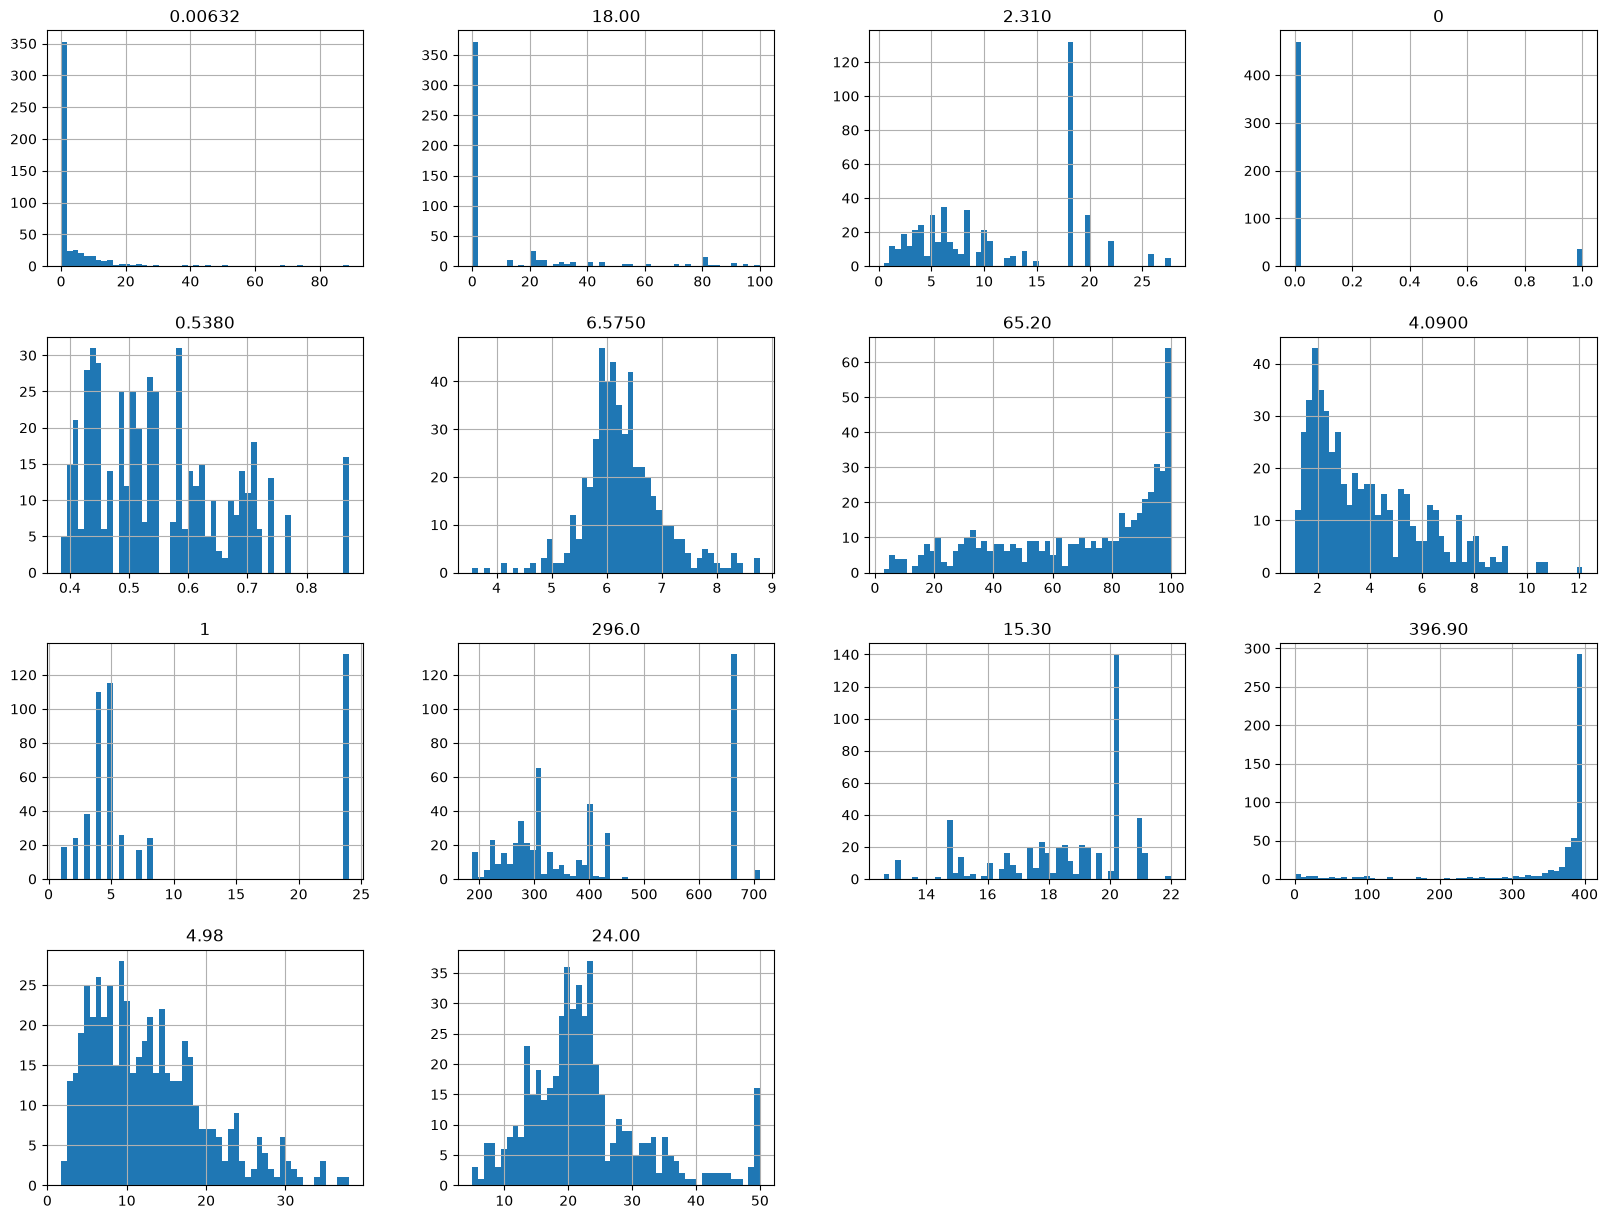

In [18]:
# حساب الملخص الإحصائي للداتا
print(dp.describe())
#رسم هيستجرام للداتا 
dp.hist(bins=50, figsize=(20,15))


In [19]:
#حساب الارتباطات بين النتغيرات 
#correlations between numerical features
dp.corr()

,0.00632,18.00,2.310,0,0.5380,6.5750,65.20,4.0900,1,296.0,15.30,396.90,4.98,24.00
0.00632,1.000000,-0.200283,0.406251,-0.056132,0.420934,-0.218978,0.352701,-0.379627,0.625396,0.582568,0.289394,-0.384839,0.455329,-0.388249
18.00,-0.200283,1.000000,-0.534022,-0.042550,-0.516574,0.311835,-0.569524,0.664395,-0.311717,-0.314351,-0.391713,0.175319,-0.412894,0.360393
2.310,0.406251,-0.534022,1.000000,0.062350,0.764556,-0.391330,0.645543,-0.708848,0.594167,0.720561,0.380955,-0.356506,0.602737,-0.484126
0,-0.056132,-0.042550,0.062350,1.000000,0.091134,0.091497,0.086461,-0.099109,-0.007907,-0.035965,-0.122570,0.049040,-0.054576,0.175364
0.5380,0.420934,-0.516574,0.764556,0.091134,1.000000,-0.302127,0.731461,-0.769221,0.611758,0.668141,0.188918,-0.380006,0.591262,-0.427295
6.5750,-0.218978,0.311835,-0.391330,0.091497,-0.302127,1.000000,-0.240211,0.205170,-0.209277,-0.291680,-0.355116,0.127754,-0.613734,0.695365
65.20,0.352701,-0.569524,0.645543,0.086461,0.731461,-0.240211,1.000000,-0.747872,0.456232,0.506527,0.261724,-0.273486,0.602782,-0.376932
4.0900,-0.379627,0.664395,-0.708848,-0.099109,-0.769221,0.205170,-0.747872,1.000000,-0.494798,-0.534492,-0.232561,0.291451,-0.497277,0.249896
1,0.625396,-0.311717,0.594167,-0.007907,0.611758,-0.209277,0.456232,-0.494798,1.000000,0.910202,0.463322,-0.444065,0.487608,-0.381690
296.0,0.582568,-0.314351,0.720561,-0.035965,0.668141,-0.291680,0.506527,-0.534492,0.910202,1.000000,0.460100,-0.441505,0.543435,-0.468543


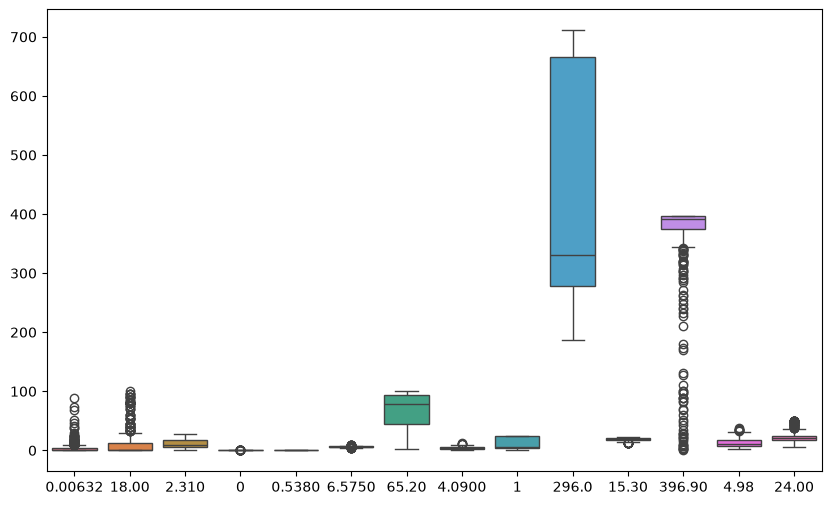

In [20]:

plt.figure(figsize=(10, 6))
sns.boxplot(data=dp)
plt.show()

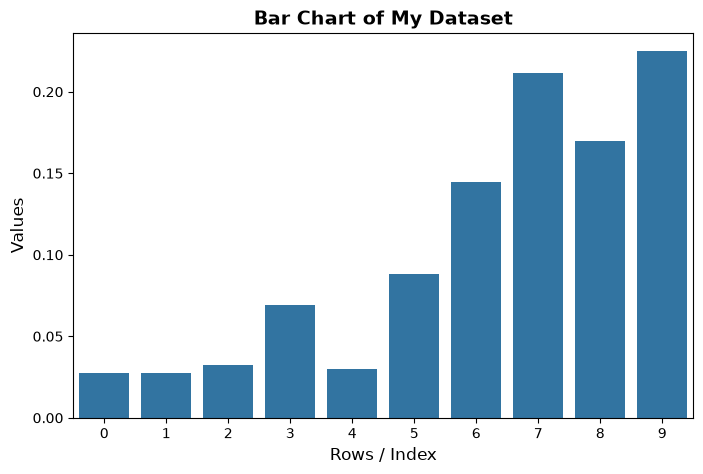

<Figure size 800x500 with 0 Axes>

In [21]:
#تحديد الحجم ومساحه الرسم
plt.figure(figsize=(8, 5))
# رسم الاعمده باول 10 قيم من الداتا
sns.barplot(x=dp.index[:10], y=dp.iloc[:10, 0])
#  تخصيص العناوين والتسميات
plt.title('Bar Chart of My Dataset', fontsize=14, fontweight='bold')
plt.xlabel('Rows / Index', fontsize=12)
plt.ylabel('Values', fontsize=12)
plt.figure(figsize=(8, 5))
plt.savefig('bar_plot_task3.png', dpi=300, bbox_inches='tight')
plt.show()

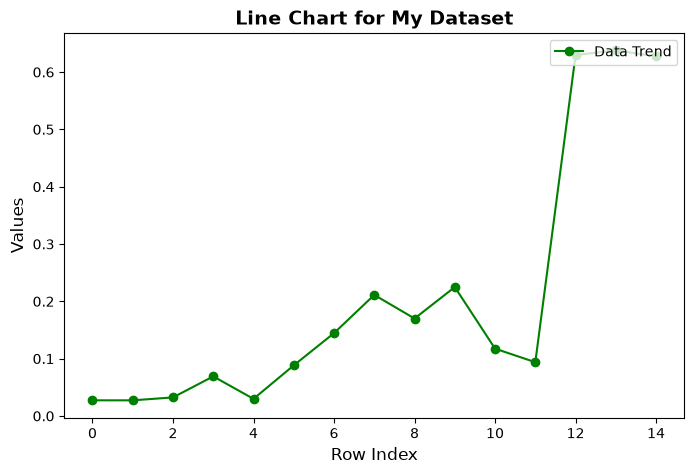

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(dp.index[:15], dp.iloc[:15, 0], marker='o', color='green', label='Data Trend')
plt.title('Line Chart for My Dataset', fontsize=14, fontweight='bold')
plt.xlabel('Row Index', fontsize=12)
plt.ylabel('Values', fontsize=12)
plt.legend(loc='upper right')
plt.savefig('line_chart_task3.png', dpi=300, bbox_inches='tight')
plt.show()

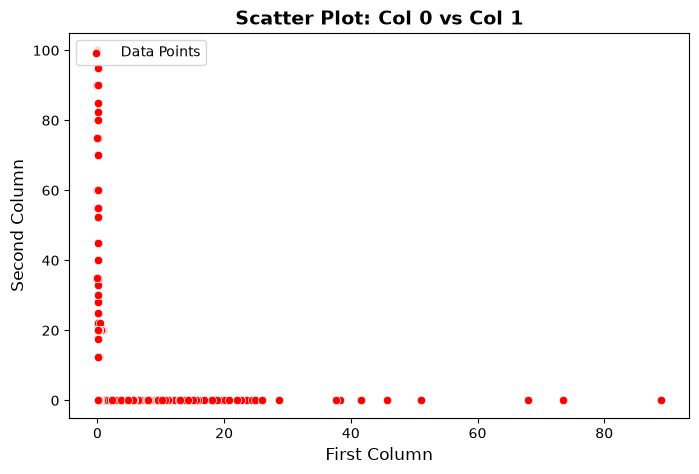

In [23]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=dp.iloc[:, 0], y=dp.iloc[:, 1], color='red', label='Data Points')
plt.title('Scatter Plot: Col 0 vs Col 1', fontsize=14, fontweight='bold')
plt.xlabel('First Column', fontsize=12)
plt.ylabel('Second Column', fontsize=12)
plt.legend(loc='upper left')
plt.savefig('scatter_plot_task3.png', dpi=300, bbox_inches='tight')
plt.show()

In [24]:
from sklearn.model_selection import train_test_split
X = dp.iloc[:, :-1]  # كل الأعمدة كمستقلات
y = dp.iloc[:, -1]   # العمود الأخير كهدف للتوقع
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (404, 13)
Testing shape: (101, 13)


In [25]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model = LinearRegression()
print("done:")

done:


In [26]:
# 1. تدريب النموذج من جديد
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

from sklearn.metrics import mean_squared_error, r2_score
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("R-squared (R2 Score):", r2)

Mean Squared Error (MSE): 19.37904111613691
R-squared (R2 Score): 0.6522201888666173


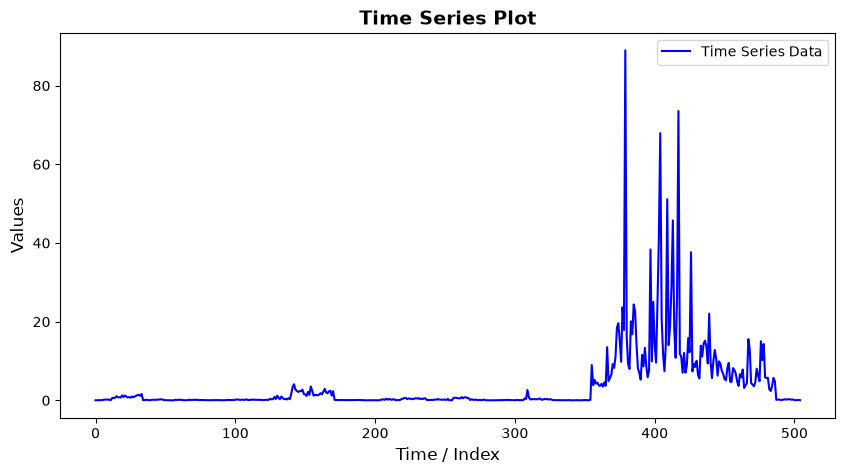

In [27]:

plt.figure(figsize=(10, 5))
plt.plot(dp.index, dp.iloc[:, 0], color='blue', label='Time Series Data')

plt.title('Time Series Plot', fontsize=14, fontweight='bold')
plt.xlabel('Time / Index', fontsize=12)
plt.ylabel('Values', fontsize=12)
plt.legend()

plt.show()

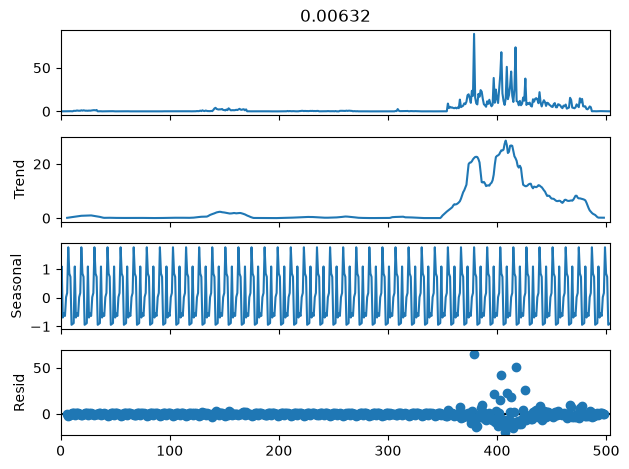

In [28]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    dp.iloc[:, 0], model='additive', period=12
)

decomposition.plot()
plt.show()

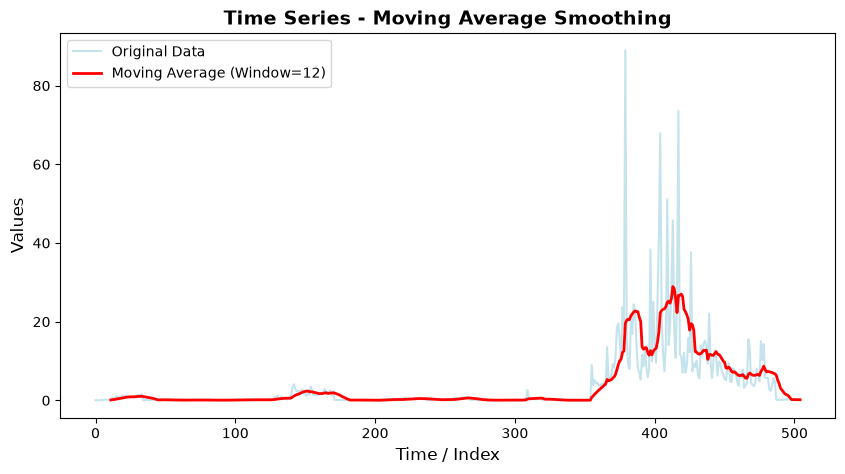

In [29]:

window_size = 12
rolling_avg = dp.iloc[:, 0].rolling(window=window_size).mean()
plt.figure(figsize=(10, 5))
plt.plot(
    dp.index, dp.iloc[:, 0], color='lightblue', label='Original Data', alpha=0.7
)
plt.plot(
    dp.index,
    rolling_avg,
    color='red',
    linewidth=2,
    label=f'Moving Average (Window={window_size})',
)

plt.title('Time Series - Moving Average Smoothing', fontsize=14, fontweight='bold')
plt.xlabel('Time / Index', fontsize=12)
plt.ylabel('Values', fontsize=12)
plt.legend()
plt.show()

In [30]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(dp)

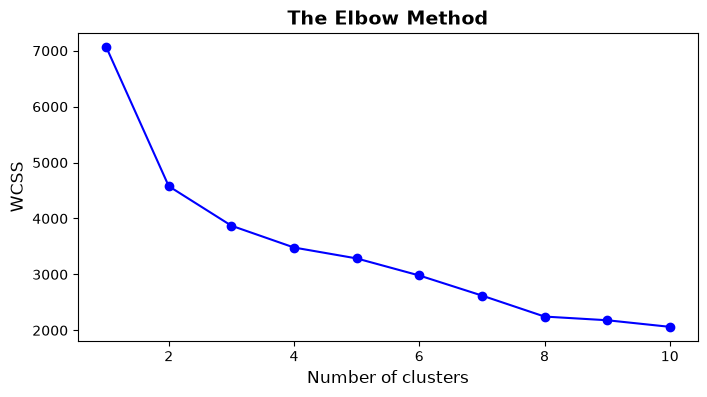

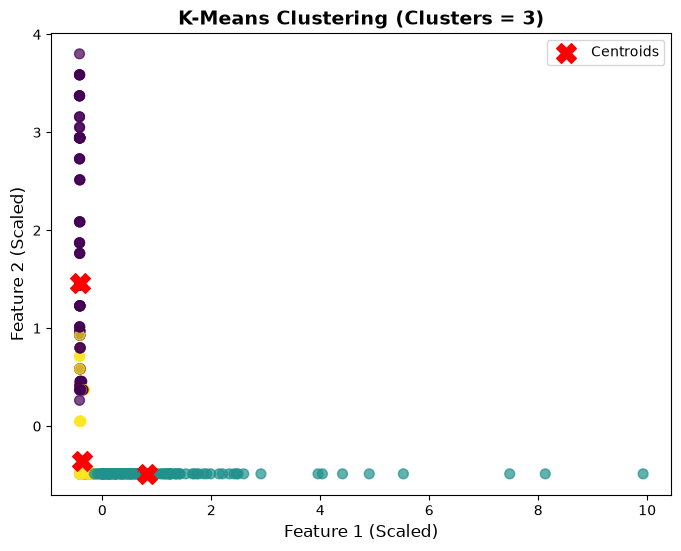

In [32]:

wcss = []
for i in range(1, 11):
  kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_)
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss, marker='o', color='b')
plt.title('The Elbow Method', fontsize=14, fontweight='bold')
plt.xlabel('Number of clusters', fontsize=12)
plt.ylabel('WCSS', fontsize=12)
plt.show()
# تحديد العدد الأمثل للكلاسترات
optimal_clusters = 3

kmeans = KMeans(n_clusters=optimal_clusters, init='k-means++', random_state=42)
y_kmeans = kmeans.fit_predict(X_scaled)

# رسم النتائج (2D Scatter Plot)
plt.figure(figsize=(8, 6))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_kmeans,
    cmap='viridis',
    s=50,
    alpha=0.7,
)

# (Centroids)
centers = kmeans.cluster_centers_
plt.scatter(
    centers[:, 0], centers[:, 1], c='red', s=200, marker='X', label='Centroids'
)

plt.title(
    f'K-Means Clustering (Clusters = {optimal_clusters})',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Feature 1 (Scaled)', fontsize=12)
plt.ylabel('Feature 2 (Scaled)', fontsize=12)
plt.legend()
plt.show()

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = dp.iloc[:, :-1]
y = dp.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)

X_train shape: (404, 13)
X_test shape: (101, 13)


In [51]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test_list = list(y_test)
classes_set = set(le.classes_)
y_test_encoded = [le.transform([val])[0] if val in classes_set else 0 for val in y_test_list]

import numpy as np
y_test = np.array(y_test_encoded)

print("y_train shape:", y_train.shape)

y_train shape: (404,)


In [52]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# 2. لو الـ y (Target) نصي، تحويله لأرقام
if y_train.dtype == 'object' or y_train.dtype.name == 'category':
    le = LabelEncoder()
    y_train = le.fit_transform(y_train)
    y_test = le.transform(y_test)

In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

for name, model in classifiers.items():
    model.fit(X_train_encoded, y_train)
    y_pred = model.predict(X_test_encoded)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    
    print(f"--- {name} ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}\n")

c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1469: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\skl

--- Logistic Regression ---
Accuracy:  0.0099
Precision: 0.0099
Recall:    0.0099
F1-score:  0.0099

--- Decision Tree ---
Accuracy:  0.0000
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000



c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\ensemble\_forest.py:811: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\tree\_classes.py:289: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\tree\_classes.py:289: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\tree\_classes.py:289: UserWar

--- Random Forest ---
Accuracy:  0.0099
Precision: 0.0099
Recall:    0.0099
F1-score:  0.0099



c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\tree\_classes.py:289: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\tree\_classes.py:289: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\tree\_classes.py:289: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\TEFA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\tree\_classes.py:289: UserWarnin

In [54]:
# حفظ البيانات المعالجة والجاهزة للعرض
dp.to_csv('cleaned_data_for_powerbi.csv', index=False)
print( "cleaned_data_for_powerbi.csv")

cleaned_data_for_powerbi.csv
